First 5 rows:
         Date    Open    High     Low   Close    Adj Close  Volume
0  1980-03-17  1380.0  1460.0  1380.0  1380.0  1379.698486       0
1  1980-03-18  1380.0  1420.0  1340.0  1340.0  1339.707153       0
2  1980-03-19  1540.0  1620.0  1540.0  1540.0  1539.663452       0
3  1980-03-20  1540.0  1600.0  1520.0  1520.0  1519.667847       0
4  1980-03-21  1520.0  1600.0  1520.0  1520.0  1519.667847       0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10098 entries, 0 to 10097
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10098 non-null  object 
 1   Open       10098 non-null  float64
 2   High       10098 non-null  float64
 3   Low        10098 non-null  float64
 4   Close      10098 non-null  float64
 5   Adj Close  10098 non-null  float64
 6   Volume     10098 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 552.4+ KB

Statistical Summary:
        

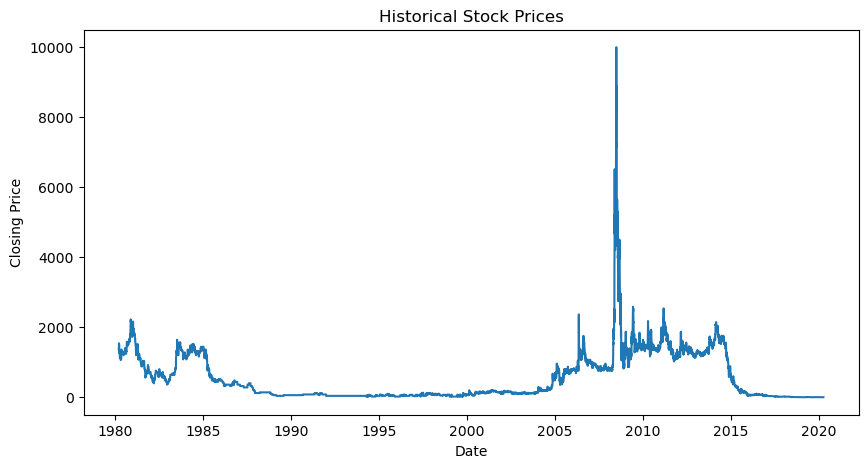

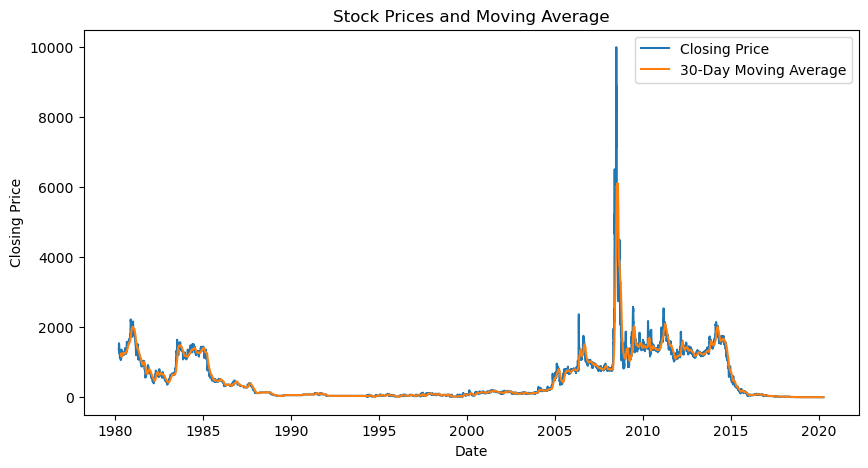

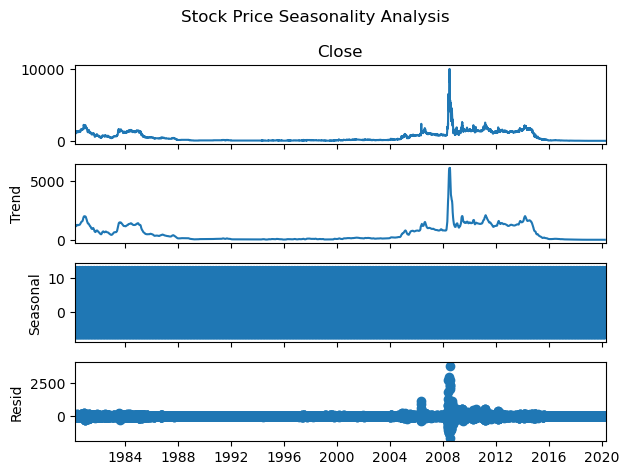


Correlation Matrix:
               Open      High       Low     Close  Adj Close    Volume
Open       1.000000  0.997401  0.997070  0.996081   0.996081 -0.043782
High       0.997401  1.000000  0.995013  0.996991   0.996991 -0.043695
Low        0.997070  0.995013  1.000000  0.997860   0.997860 -0.044998
Close      0.996081  0.996991  0.997860  1.000000   1.000000 -0.044026
Adj Close  0.996081  0.996991  0.997860  1.000000   1.000000 -0.044026
Volume    -0.043782 -0.043695 -0.044998 -0.044026  -0.044026  1.000000


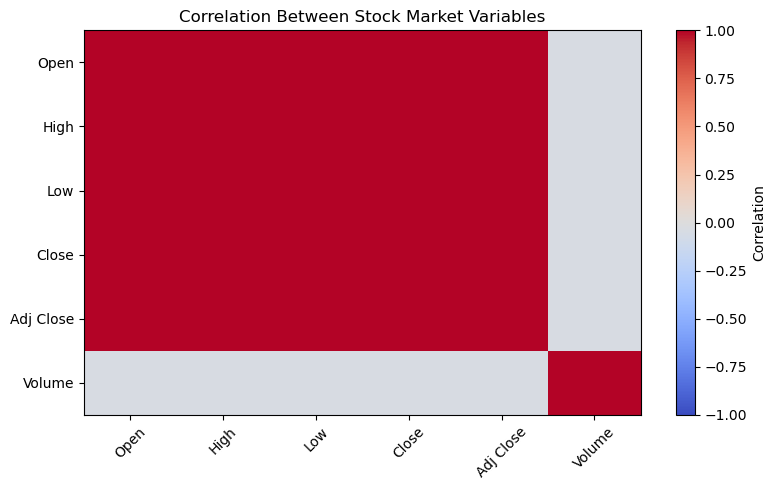


Forecasted Stock Prices for Next 10 Business Days:
2020-04-02    1.650671
2020-04-03    1.646099
2020-04-06    1.660136
2020-04-07    1.682647
2020-04-08    1.679059
2020-04-09    1.675677
2020-04-10    1.678900
2020-04-13    1.683802
2020-04-14    1.682259
2020-04-15    1.681089
Freq: B, dtype: float64


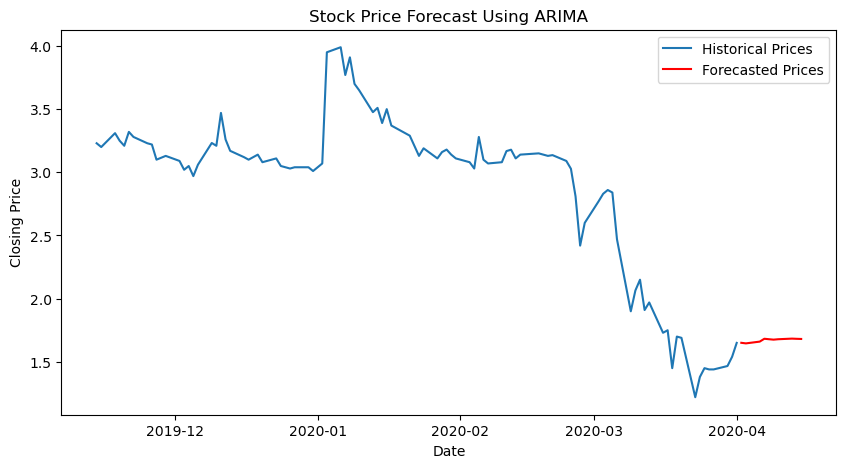

In [2]:
# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose

# 2. Load and explore the dataset
df = pd.read_csv("Stock_Prices.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

# 3. Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date')
df = df.drop_duplicates(subset='Date')
df = df.set_index('Date')

# Use closing price for analysis
price = df['Close'].dropna().sort_index()

# 4. Plot historical stock prices
plt.figure(figsize=(10, 5))
plt.plot(price)
plt.title("Historical Stock Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

# 5. Calculate and plot moving average
moving_average = price.rolling(window=30).mean()

plt.figure(figsize=(10, 5))
plt.plot(price, label="Closing Price")
plt.plot(moving_average, label="30-Day Moving Average")
plt.title("Stock Prices and Moving Average")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.show()

# 6. Seasonality analysis
seasonal_data = price.asfreq('B').interpolate(method='time')

decomposition = seasonal_decompose(
    seasonal_data,
    model='additive',
    period=30
)

decomposition.plot()
plt.suptitle("Stock Price Seasonality Analysis")
plt.tight_layout()
plt.show()

# 7. Correlation between stock prices and other variables
numeric_data = df.select_dtypes(include='number')
correlation = numeric_data.corr()

print("\nCorrelation Matrix:")
print(correlation)

plt.figure(figsize=(8, 5))
plt.imshow(correlation, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Between Stock Market Variables")
plt.tight_layout()
plt.show()

# 8. Forecast future stock prices using ARIMA
# Convert to business-day frequency to support date-based forecasting
forecast_data = price.asfreq('B').interpolate(method='time')

model = ARIMA(forecast_data, order=(5, 1, 0))
model_fit = model.fit()

forecast_values = model_fit.forecast(steps=10)

# Display forecasted values
future_dates = pd.bdate_range(
    start=forecast_data.index[-1] + pd.offsets.BDay(1),
    periods=10
)

forecast = pd.Series(forecast_values.values, index=future_dates)

print("\nForecasted Stock Prices for Next 10 Business Days:")
print(forecast)

# Plot historical and forecasted prices
plt.figure(figsize=(10, 5))
plt.plot(forecast_data.tail(100), label="Historical Prices")
plt.plot(forecast, label="Forecasted Prices", color="red")
plt.title("Stock Price Forecast Using ARIMA")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.show()